Sofia Anaya Palafox

738594

Ingeniería Financiera

#50

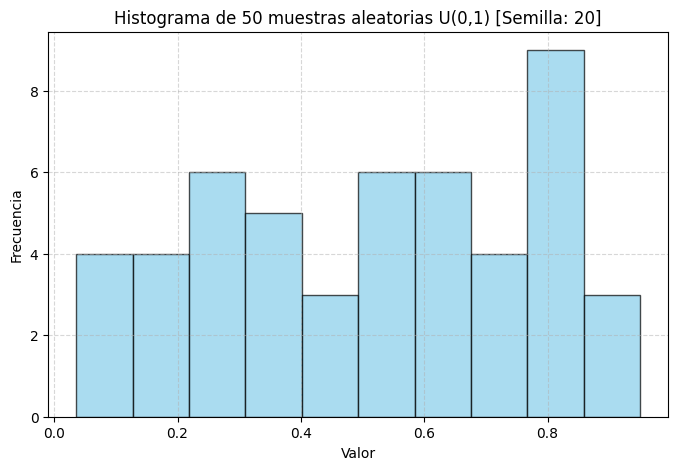

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(20)

# Generar 50 muestras de U(0,1)
muestras = np.random.uniform(0, 1, 50)

# Crear el histograma
plt.figure(figsize=(8, 5))
plt.hist(muestras, bins=10, edgecolor='black', alpha=0.7, color='skyblue')
plt.title('Histograma de 50 muestras aleatorias U(0,1) [Semilla: 20]')
plt.xlabel('Valor')
plt.ylabel('Frecuencia')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

#100

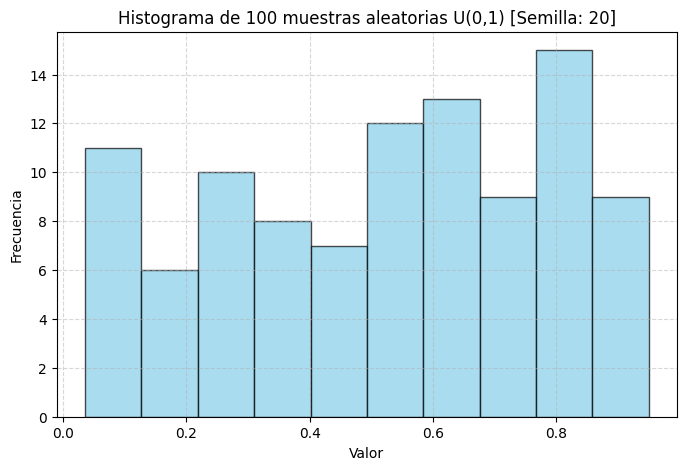

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(20)

# Generar 100 muestras de U(0,1)
muestras = np.random.uniform(0, 1, 100)

# Crear el histograma
plt.figure(figsize=(8, 5))
plt.hist(muestras, bins=10, edgecolor='black', alpha=0.7, color='skyblue')
plt.title('Histograma de 100 muestras aleatorias U(0,1) [Semilla: 20]')
plt.xlabel('Valor')
plt.ylabel('Frecuencia')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

# 500

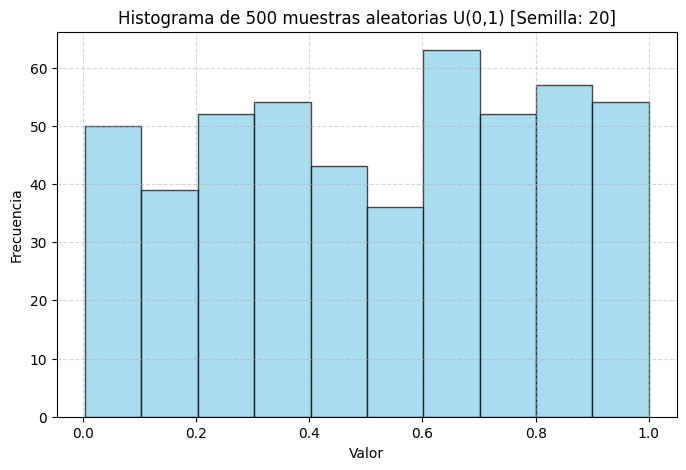

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(20)

# Generar 500 muestras de U(0,1)
muestras = np.random.uniform(0, 1, 500)

# Crear el histograma
plt.figure(figsize=(8, 5))
plt.hist(muestras, bins=10, edgecolor='black', alpha=0.7, color='skyblue')
plt.title('Histograma de 500 muestras aleatorias U(0,1) [Semilla: 20]')
plt.xlabel('Valor')
plt.ylabel('Frecuencia')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

#1000

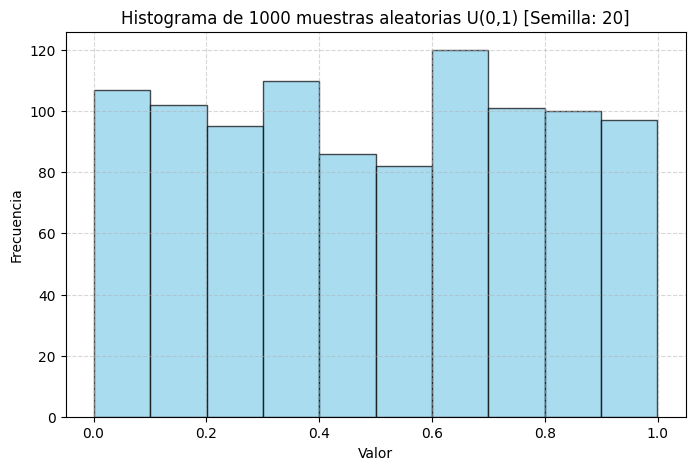

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(20)

# Generar 1000 muestras de U(0,1)
muestras = np.random.uniform(0, 1, 1000)

# Crear el histograma
plt.figure(figsize=(8, 5))
plt.hist(muestras, bins=10, edgecolor='black', alpha=0.7, color='skyblue')
plt.title('Histograma de 1000 muestras aleatorias U(0,1) [Semilla: 20]')
plt.xlabel('Valor')
plt.ylabel('Frecuencia')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

# 100,000

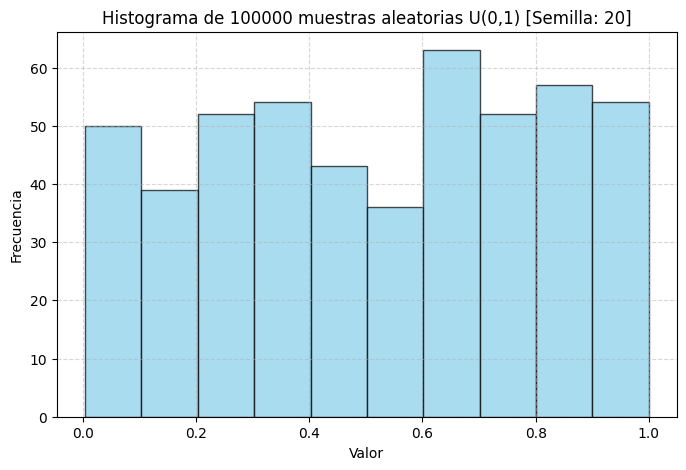

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(20)

# Generar 100000 muestras de U(0,1)
muestras = np.random.uniform(0, 1, 500)

# Crear el histograma
plt.figure(figsize=(8, 5))
plt.hist(muestras, bins=10, edgecolor='black', alpha=0.7, color='skyblue')
plt.title('Histograma de 100000 muestras aleatorias U(0,1) [Semilla: 20]')
plt.xlabel('Valor')
plt.ylabel('Frecuencia')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

# Mismo proceso con números deterministas

/tmp/ipykernel_876/1901500937.py:17: UserWarning: The balance properties of Sobol' points require n to be a power of 2.
  muestras_sobol = sampler.random(n=N).flatten()


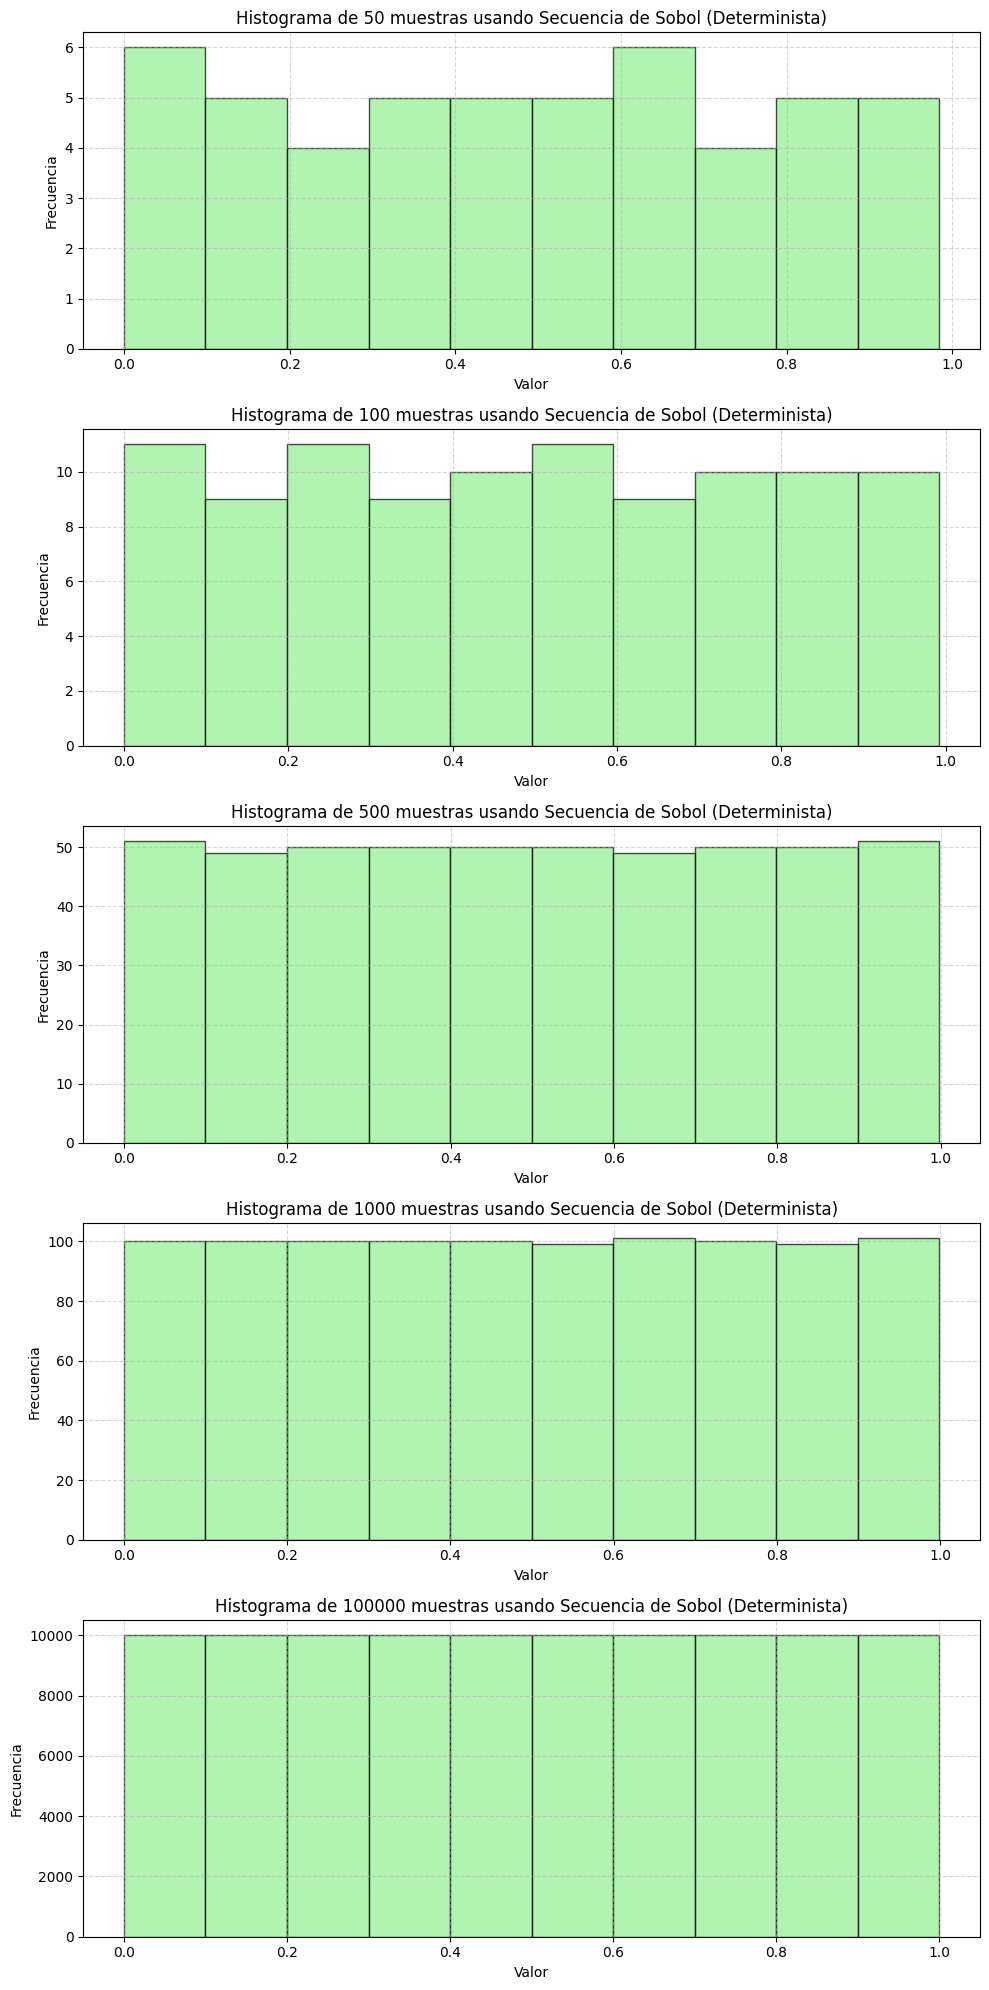

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import qmc

# Tamaños de muestra
tamanos = [50, 100, 500, 1000, 100000]

# Gráficos para comparar
fig, axes = plt.subplots(len(tamaños), 1, figsize=(10, 20))

for i, N in enumerate(tamaños):
    # Inicializar el generador Sobol para 1 dimensión
    # Usamos scrambles=False para asegurar que sea completamente determinista
    sampler = qmc.Sobol(d=1, scramble=False)

    # Generar N muestras en el intervalo [0, 1)
    muestras_sobol = sampler.random(n=N).flatten()
    #En Python, el método flatten() convierte un
    #array o matriz multidimensional (de NumPy) en un array de una sola dimensión (1D)

    # Graficar el histograma
    axes[i].hist(muestras_sobol, bins=10, edgecolor='black', alpha=0.7, color='lightgreen')
    axes[i].set_title(f'Histograma de {N} muestras usando Secuencia de Sobol (Determinista)')
    axes[i].set_xlabel('Valor')
    axes[i].set_ylabel('Frecuencia')
    axes[i].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

# Con Monte Carlo mostrar el valor promedio de una función con m= [100, 500, 1000]

In [ ]:
import numpy as np
from scipy.stats import qmc

# Definir la función a integrar
def f(x):
    return x**2

# Tamaños de muestra
m_valores = [100, 500, 1000, 5000]
valor_real = 1/3

print(f"Valor real teórico de la integral: {valor_real:.4f}\n")

# --- 1. Monte Carlo Estándar (Pseudo-aleatorio) ---
print("--- MONTE CARLO ESTÁNDAR (Semilla = 20) ---")
for m in m_valores:
    x_random = np.random.uniform(0, 1, m)
    y_random = f(x_random)
    promedio_mc = np.mean(y_random)
    error_mc = np.abs(promedio_mc - valor_real)
    print(f"M = {m:4d} | Valor aproximado: {promedio_mc:.6f} | Error absoluto: {error_mc:.6f}")

print("\n--- QUASI-MONTE CARLO (Sobol Determinista) ---")
# --- 2. Quasi-Monte Carlo (Sobol) ---
for m in m_valores:
    sampler = qmc.Sobol(d=1, scramble=True)
    x_sobol = sampler.random(n=m)
    y_sobol = f(x_sobol)
    promedio_qmc = np.mean(y_sobol)
    error_qmc = np.abs(promedio_qmc - valor_real)
    print(f"M = {m:4d} | Valor aproximado: {promedio_qmc:.6f} | Error absoluto: {error_qmc:.6f}")

Valor real teórico de la integral: 0.3333

--- MONTE CARLO ESTÁNDAR (Semilla = 20) ---
M =  100 | Valor aproximado: 0.314059 | Error absoluto: 0.019274
M =  500 | Valor aproximado: 0.341542 | Error absoluto: 0.008209
M = 1000 | Valor aproximado: 0.340729 | Error absoluto: 0.007395
M = 5000 | Valor aproximado: 0.332396 | Error absoluto: 0.000937

--- QUASI-MONTE CARLO (Sobol Determinista) ---
M =  100 | Valor aproximado: 0.330851 | Error absoluto: 0.002483
M =  500 | Valor aproximado: 0.333064 | Error absoluto: 0.000269
M = 1000 | Valor aproximado: 0.333155 | Error absoluto: 0.000179
M = 5000 | Valor aproximado: 0.333327 | Error absoluto: 0.000007


/tmp/ipykernel_876/839041253.py:27: UserWarning: The balance properties of Sobol' points require n to be a power of 2.
  x_sobol = sampler.random(n=m)


/tmp/ipykernel_876/2593073946.py:10: UserWarning: The balance properties of Sobol' points require n to be a power of 2.
  u = sampler.random(n=1000)


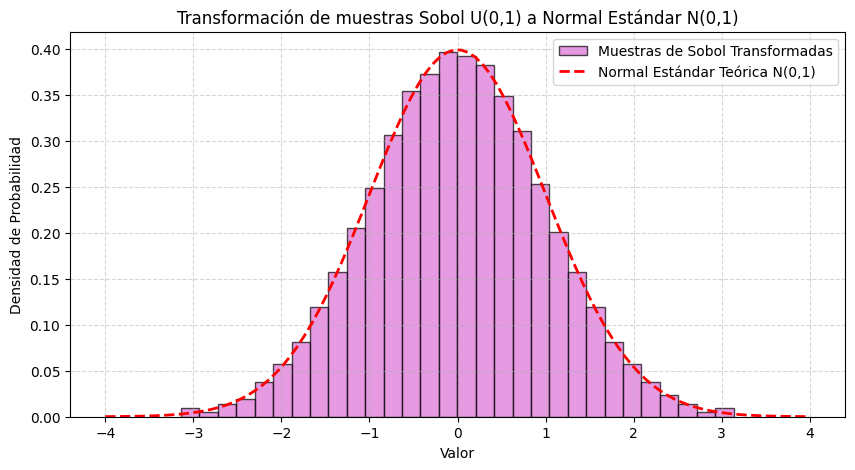

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import qmc, norm

# Inicializar generador Sobol determinista
sampler = qmc.Sobol(d=1, scramble=True)

# Generar muestras uniformes u en (0, 1)
u = sampler.random(n=1000)

# Transformar a distribución normal usando la inversa de la CDF (Función Cuantil)
normal_samples = norm.ppf(u)

# Graficar el resultado para comprobar la distribución normal
plt.figure(figsize=(10, 5))
plt.hist(normal_samples, bins=30, edgecolor='black', alpha=0.7, color='orchid', density=True, label='Muestras de Sobol Transformadas')

# Graficar la curva teórica de la normal estándar para comparar
x_axis = np.linspace(-4, 4, 100)
plt.plot(x_axis, norm.pdf(x_axis), 'r--', lw=2, label='Normal Estándar Teórica N(0,1)')

plt.title('Transformación de muestras Sobol U(0,1) a Normal Estándar N(0,1)')
plt.xlabel('Valor')
plt.ylabel('Densidad de Probabilidad')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

### Simulación de la Utilidad de una Empresa ($N(50, 10)$)
Queremos calcular $P(X > 60)$ usando **Monte Carlo** y **Quasi-Monte Carlo (Sobol)** para $m \in [10, 100, 1000, 10000]$.

In [ ]:
import numpy as np
from scipy.stats import qmc, norm

# Parámetros del problema
mu = 50
sigma = 10
umbral = 60

# Valor teórico exacto usando la función de supervivencia (sf = 1 - cdf)
valor_real = norm.sf(umbral, loc=mu, scale=sigma)

m_valores = [10, 100, 1000, 10000]

print(f"Probabilidad teórica exacta P(X > 60): {valor_real:.6f} ({valor_real*100:.4f}%)\n")

# --- 1. Monte Carlo Estándar ---
print("--- MONTE CARLO ESTÁNDAR ---")
np.random.seed(20) # Fijamos semilla para reproducibilidad
for m in m_valores:
    # Muestras directas de la distribución normal N(50, 10)
    muestras_mc = np.random.normal(loc=mu, scale=sigma, size=m)
    # Indicadora: 1 si es mayor que 60, 0 de lo contrario
    exitos = muestras_mc > umbral
    prob_mc = np.mean(exitos)
    error_mc = np.abs(prob_mc - valor_real)
    print(f"M = {m:5d} | Prob. aproximada: {prob_mc:.6f} | Error absoluto: {error_mc:.6f}")

# --- 2. Quasi-Monte Carlo (Sobol) ---
print("\n--- QUASI-MONTE CARLO (Sobol) ---")
for m in m_valores:
    # Inicializar generador Sobol
    sampler = qmc.Sobol(d=1, scramble=True, seed=20)
    u = sampler.random(n=m).flatten()

    # Transformar las muestras uniformes de Sobol a la normal N(50, 10)
    muestras_qmc = norm.ppf(u, loc=mu, scale=sigma)

    # Indicadora
    exitos_qmc = muestras_qmc > umbral
    prob_qmc = np.mean(exitos_qmc)
    error_qmc = np.abs(prob_qmc - valor_real)
    print(f"M = {m:5d} | Prob. aproximada: {prob_qmc:.6f} | Error absoluto: {error_qmc:.6f}")

Probabilidad teórica exacta P(X > 60): 0.158655 (15.8655%)

--- MONTE CARLO ESTÁNDAR ---
M =    10 | Prob. aproximada: 0.000000 | Error absoluto: 0.158655
M =   100 | Prob. aproximada: 0.180000 | Error absoluto: 0.021345
M =  1000 | Prob. aproximada: 0.163000 | Error absoluto: 0.004345
M = 10000 | Prob. aproximada: 0.161200 | Error absoluto: 0.002545

--- QUASI-MONTE CARLO (Sobol) ---
M =    10 | Prob. aproximada: 0.100000 | Error absoluto: 0.058655
M =   100 | Prob. aproximada: 0.160000 | Error absoluto: 0.001345
M =  1000 | Prob. aproximada: 0.160000 | Error absoluto: 0.001345
M = 10000 | Prob. aproximada: 0.158500 | Error absoluto: 0.000155


/tmp/ipykernel_876/630709423.py:33: UserWarning: The balance properties of Sobol' points require n to be a power of 2.
  u = sampler.random(n=m).flatten()


# d = 252

ahora haz una call europea y una call asíática con qmc.sobol(d=252...) y los parámetros s0=100, r=5%, sigma=20%, T=1, n=252, K=100 y M=1024

In [1]:
import numpy as np
from scipy.stats import qmc, norm

# Parámetros del problema
S0 = 100.0
r = 0.05
sigma = 0.20
T = 1.0
n = 252  # Pasos de tiempo (d = 252)
K = 100.0
M = 1024  # Número de simulaciones (potencia de 2)
dt = T / n

# 1. Generar muestras Quasi-Monte Carlo (Sobol)
# d es la dimensión del problema, que corresponde a los n pasos de tiempo (d = 252)
sampler = qmc.Sobol(d=n, scramble=True, seed=20)

# Generar M puntos uniformes en [0, 1)^252
u = sampler.random(n=M)

# Transformar las muestras uniformes a Normales Estándar independientes N(0, 1)
# Z tendrá forma (M, n)
Z = norm.ppf(u)

# 2. Simulación de las trayectorias del precio del activo (Movimiento Browniano Geométrico)
# dt es el paso de tiempo
# drift y difusión
drift = (r - 0.5 * sigma**2) * dt
difusion = sigma * np.sqrt(dt)

# Inicializar matriz de trayectorias (M, n + 1) para incluir el precio inicial S0
S = np.zeros((M, n + 1))
S[:, 0] = S0

# Generar secuencialmente los precios para cada paso
for t in range(1, n + 1):
    S[:, t] = S[:, t - 1] * np.exp(drift + difusion * Z[:, t - 1])

# 3. Valoración de la Opción Call Europea
# Depende únicamente del precio final S_T (última columna)
ST = S[:, -1]
payoff_europea = np.maximum(ST - K, 0)
precio_europea_qmc = np.exp(-r * T) * np.mean(payoff_europea)

# 4. Valoración de la Opción Call Asiática
# Depende del promedio de la trayectoria del precio (excluyendo o incluyendo S0; usualmente se promedia desde t=1 a n o de 0 a n. Usaremos la media de 1 a n)
promedio_trayectoria = np.mean(S[:, 1:], axis=1)
payoff_asiatica = np.maximum(promedio_trayectoria - K, 0)
precio_asiatica_qmc = np.exp(-r * T) * np.mean(payoff_asiatica)

# Mostrar resultados
print(f"--- RESULTADOS DE VALORACIÓN QMC (M = {M}) ---")
print(f"Precio Call Europea: {precio_europea_qmc:.4f}")
print(f"Precio Call Asiática: {precio_asiatica_qmc:.4f}")

--- RESULTADOS DE VALORACIÓN QMC (M = 1024) ---
Precio Call Europea: 10.5485
Precio Call Asiática: 5.8309


In [2]:
import numpy as np
import pandas as pd
from scipy.stats import norm, qmc

# --- 1. Valor Teórico de Referencia (Black-Scholes para la Europea) ---
def black_scholes_call(S0, K, r, sigma, T):
    d1 = (np.log(S0 / K) + (r + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)
    return S0 * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d2)

bs_europea = black_scholes_call(S0, K, r, sigma, T)

# Para la Asiática Aritmética no hay fórmula analítica exacta simple,
# estimamos su valor de alta precisión (Benchmark) con un Monte Carlo estándar masivo (M = 1,000,000)
M_benchmark = 1000000
np.random.seed(42)
Z_bench = np.random.normal(0, 1, (M_benchmark, n))
S_bench = np.zeros((M_benchmark, n + 1))
S_bench[:, 0] = S0
for t in range(1, n + 1):
    S_bench[:, t] = S_bench[:, t - 1] * np.exp(drift + difusion * Z_bench[:, t - 1])
promedio_bench = np.mean(S_bench[:, 1:], axis=1)
bs_asiatica_benchmark = np.exp(-r * T) * np.mean(np.maximum(promedio_bench - K, 0))

# --- 2. Monte Carlo Estándar con M = 1024 ---
np.random.seed(20)  # Misma semilla para consistencia
Z_mc = np.random.normal(0, 1, (M, n))
S_mc = np.zeros((M, n + 1))
S_mc[:, 0] = S0
for t in range(1, n + 1):
    S_mc[:, t] = S_mc[:, t - 1] * np.exp(drift + difusion * Z_mc[:, t - 1])

# Europea MC
ST_mc = S_mc[:, -1]
mc_europea = np.exp(-r * T) * np.mean(np.maximum(ST_mc - K, 0))

# Asiática MC
promedio_mc = np.mean(S_mc[:, 1:], axis=1)
mc_asiatica = np.exp(-r * T) * np.mean(np.maximum(promedio_mc - K, 0))

# --- 3. Quasi-Monte Carlo (QMC Sobol) con M = 1024 (Valores ya calculados previamente) ---
qmc_europea = precio_europea_qmc
qmc_asiatica = precio_asiatica_qmc

# --- Creación de la Tabla Comparativa ---
data = {
    "Métrica / Método": [
        "Call Europea (Precio)",
        "Diferencia Absoluta (vs BS)",
        "Diferencia Porcentual (vs BS)",
        "Call Asiática (Precio)",
        "Diferencia Absoluta (vs Bench)",
        "Diferencia Porcentual (vs Bench)"
    ],
    "Referencia / BS": [
        f"{bs_europea:.5f}",
        "-",
        "-",
        f"{bs_asiatica_benchmark:.5f}",
        "-",
        "-"
    ],
    "Monte Carlo (MC)": [
        f"{mc_europea:.5f}",
        f"{abs(mc_europea - bs_europea):.5f}",
        f"{abs(mc_europea - bs_europea)/bs_europea*100:.3f}%",
        f"{mc_asiatica:.5f}",
        f"{abs(mc_asiatica - bs_asiatica_benchmark):.5f}",
        f"{abs(mc_asiatica - bs_asiatica_benchmark)/bs_asiatica_benchmark*100:.3f}%"
    ],
    "Quasi-Monte Carlo (QMC)": [
        f"{qmc_europea:.5f}",
        f"{abs(qmc_europea - bs_europea):.5f}",
        f"{abs(qmc_europea - bs_europea)/bs_europea*100:.3f}%",
        f"{qmc_asiatica:.5f}",
        f"{abs(qmc_asiatica - bs_asiatica_benchmark):.5f}",
        f"{abs(qmc_asiatica - bs_asiatica_benchmark)/bs_asiatica_benchmark*100:.3f}%"
    ]
}

df_comparativo = pd.DataFrame(data)
display(df_comparativo)

,Métrica / Método,Referencia / BS,Monte Carlo (MC),Quasi-Monte Carlo (QMC)
0,Call Europea (Precio),10.45058,11.63881,10.54846
1,Diferencia Absoluta (vs BS),-,1.18823,0.09788
2,Diferencia Porcentual (vs BS),-,11.370%,0.937%
3,Call Asiática (Precio),5.76827,6.41051,5.83091
4,Diferencia Absoluta (vs Bench),-,0.64224,0.06264
5,Diferencia Porcentual (vs Bench),-,11.134%,1.086%
